In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [3]:
df = pd.read_csv('ecommerce_data.csv')

In [4]:
df.head()

,CustomerID,InvoiceDate,Quantity,UnitPrice,TotalAmount,Country,ProductCategory
0,C0045,2022-08-24 00:00:00,2,39.69,79.39,UK,Books
1,C0757,2022-07-01 00:00:00,1,414.09,414.09,Netherlands,Sports
2,C1643,2022-01-05 00:00:00,1,358.44,358.44,NaN,Sports
3,C0133,2023-07-01 00:00:00,1,150.21,150.21,UK,Clothing
4,C0941,2022-12-10 00:00:00,1,222.65,222.65,UK,Sports


In [5]:
df.columns

Index(['CustomerID', 'InvoiceDate', 'Quantity', 'UnitPrice', 'TotalAmount',
       'Country', 'ProductCategory'],
      dtype='object')

In [6]:
#checking the data type
df['Quantity'].info()

<class 'pandas.core.series.Series'>
RangeIndex: 8205 entries, 0 to 8204
Series name: Quantity
Non-Null Count  Dtype
--------------  -----
8205 non-null   int64
dtypes: int64(1)
memory usage: 64.2 KB


In [7]:
df['Quantity'].describe()

count    8205.000000
mean        1.248507
std         0.792325
min        -5.000000
25%         1.000000
50%         1.000000
75%         1.000000
max         8.000000
Name: Quantity, dtype: float64

In [8]:
df['Quantity'].nunique()

13

In [9]:
df[df['Quantity'] <= 0]

,CustomerID,InvoiceDate,Quantity,UnitPrice,TotalAmount,Country,ProductCategory
32,C1302,2023-02-17 00:00:00,-5,9.32,46.60,Netherlands,Beauty
51,C1356,2022-06-16 00:00:00,-1,166.06,166.06,UK,Clothing
52,C1593,2023-03-10 00:00:00,-1,26.42,26.42,France,Home & Garden
59,C1486,2022-09-09 00:00:00,-1,303.81,303.81,France,Electronics
223,C0031,2023-02-08 00:00:00,-1,220.59,167.67,Spain,Sports
...,...,...,...,...,...,...,...
6880,C0332,2022-08-29 00:00:00,-1,289.12,289.12,Netherlands,Sports
6884,C0999,2023-04-09 00:00:00,-1,6.41,6.41,Germany,Books
6969,C1359,2022-04-24 00:00:00,-1,42.12,42.12,France,Books
7137,C0444,2022-07-22 00:00:00,-1,47.08,37.84,NaN,Books


In [10]:
negative_qty = df[df['Quantity'] < 0]

len(negative_qty)

65

the quantity column has 65 negative numbers. this could be an error or they might be products that were bought but later returned
further investigation

In [11]:
print("Total rows:", len(df))
print("Negative quantities:", (df['Quantity'] < 0).sum())
print("Zero quantities:", (df['Quantity'] == 0).sum())
print("Positive quantities:", (df['Quantity'] > 0).sum())

print("\nNegative quantity percentage:")
print((df['Quantity'] < 0).mean() * 100)

print("\nNegative quantity values:")
print(df.loc[df['Quantity'] < 0, 'Quantity'].value_counts().sort_index())

Total rows: 8205
Negative quantities: 65
Zero quantities: 0
Positive quantities: 8140

Negative quantity percentage:
0.7921998781230957

Negative quantity values:
Quantity
-5     1
-4     2
-3     1
-2     3
-1    58
Name: count, dtype: int64


In [12]:
negative_qty = df[df['Quantity'] < 0]

negative_qty.sort_values('Quantity').head(20)

,CustomerID,InvoiceDate,Quantity,UnitPrice,TotalAmount,Country,ProductCategory
32,C1302,2023-02-17 00:00:00,-5,9.32,46.60,Netherlands,Beauty
5200,C1105,2022-12-27 00:00:00,-4,180.18,720.74,France,Clothing
2731,C1648,2023-01-16 00:00:00,-4,46.14,184.55,UK,Books
5287,C0380,2022-11-26 00:00:00,-3,51.16,153.49,Netherlands,Beauty
4189,C1696,2023-07-21 00:00:00,-2,230.74,461.48,Netherlands,Home & Garden
534,C1179,2022-10-18 00:00:00,-2,82.89,165.79,UK,Beauty
6179,C1593,2022-10-19 00:00:00,-2,17.96,35.93,France,Beauty
4808,C0517,2023-07-15 00:00:00,-1,25.66,25.66,NaN,Books
4775,C1044,2022-10-07 00:00:00,-1,12.77,12.77,UK,Books
4653,C1825,2023-02-02 00:00:00,-1,12.50,12.50,UK,Books


In [13]:
negative_qty[
    ['CustomerID', 'InvoiceDate', 'Quantity',
     'UnitPrice', 'TotalAmount', 'Country', 'ProductCategory']
].head(20)

,CustomerID,InvoiceDate,Quantity,UnitPrice,TotalAmount,Country,ProductCategory
32,C1302,2023-02-17 00:00:00,-5,9.32,46.60,Netherlands,Beauty
51,C1356,2022-06-16 00:00:00,-1,166.06,166.06,UK,Clothing
52,C1593,2023-03-10 00:00:00,-1,26.42,26.42,France,Home & Garden
59,C1486,2022-09-09 00:00:00,-1,303.81,303.81,France,Electronics
223,C0031,2023-02-08 00:00:00,-1,220.59,167.67,Spain,Sports
534,C1179,2022-10-18 00:00:00,-2,82.89,165.79,UK,Beauty
595,C0547,2022-08-23 00:00:00,-1,222.06,222.06,UK,Home & Garden
704,C1599,2022-09-18 00:00:00,-1,543.75,543.75,UK,Sports
874,C1518,2022-05-20 00:00:00,-1,63.22,63.22,France,Home & Garden
1072,C1366,2023-05-22 00:00:00,-1,139.47,139.47,UK,Home & Garden


In [14]:
negative_qty[['Quantity', 'UnitPrice', 'TotalAmount']].head(20)

,Quantity,UnitPrice,TotalAmount
32,-5,9.32,46.60
51,-1,166.06,166.06
52,-1,26.42,26.42
59,-1,303.81,303.81
223,-1,220.59,167.67
534,-2,82.89,165.79
595,-1,222.06,222.06
704,-1,543.75,543.75
874,-1,63.22,63.22
1072,-1,139.47,139.47


the negative quatity does not equal a negative total amount, this is pointing towards and error in the data collected rather than product returns

In [15]:
#Checking which customers have negative Quantities

negative_by_customer = (
    negative_qty
    .groupby('CustomerID')['Quantity']
    .sum()
    .sort_values()
)

negative_by_customer.head(20)

CustomerID
C1302   -5
C1648   -4
C1105   -4
C1593   -3
C0380   -3
C1696   -2
C1179   -2
C1345   -1
C1342   -1
C0011   -1
C1356   -1
C1094   -1
C1044   -1
C1016   -1
C0999   -1
C1167   -1
C1359   -1
C1446   -1
C1402   -1
C0970   -1
Name: Quantity, dtype: int64

In [16]:
#Checking whether negative quantities are concentrated in particular product categories
negative_qty['ProductCategory'].value_counts()

ProductCategory
Sports           15
Books            13
Beauty           12
Home & Garden     9
Electronics       9
Clothing          7
Name: count, dtype: int64

In [17]:
#calculating the skewness
df['Quantity'].skew()

2.7397598751685246

our Quantity column is highly skewed to the right...this is probably because of the negative values

In [19]:
df['Quantity'].describe()

count    8205.000000
mean        1.248507
std         0.792325
min        -5.000000
25%         1.000000
50%         1.000000
75%         1.000000
max         8.000000
Name: Quantity, dtype: float64

the mean value is not so much larget than the median value, it means we do not have massive outliers

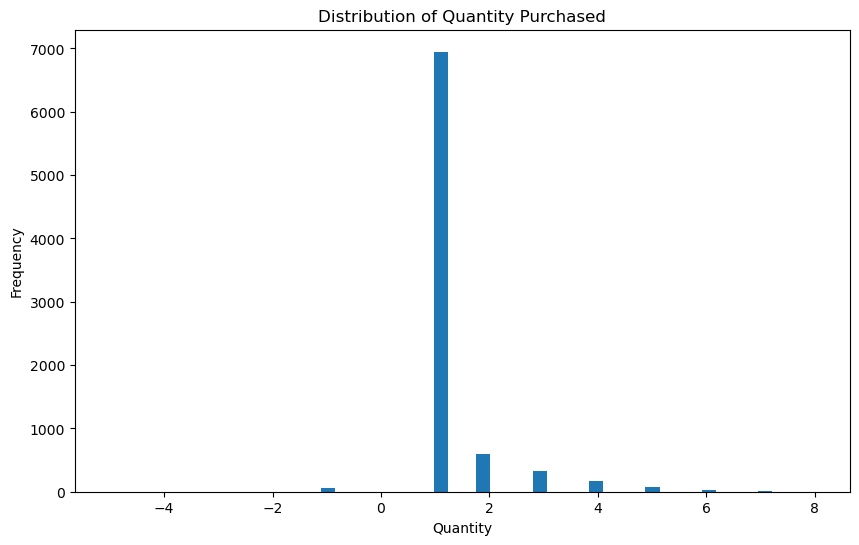

In [20]:
plt.figure(figsize=(10, 6))

plt.hist(df['Quantity'], bins=50)

plt.xlabel('Quantity')
plt.ylabel('Frequency')
plt.title('Distribution of Quantity Purchased')

plt.show()

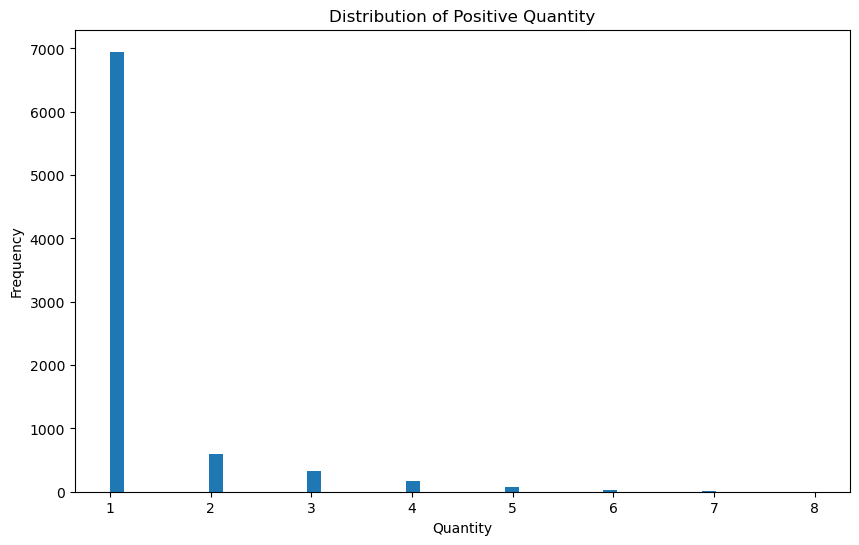

In [21]:
positive_qty = df[df['Quantity'] > 0]['Quantity']

plt.figure(figsize=(10, 6))

plt.hist(positive_qty, bins=50)

plt.xlabel('Quantity')
plt.ylabel('Frequency')
plt.title('Distribution of Positive Quantity')

plt.show()

our dataset contained negative values, so we considered only the positive values

In [30]:
df['Quantity'].value_counts().sort_index().head(20)

Quantity
-5       1
-4       2
-3       1
-2       3
-1      58
 1    6948
 2     595
 3     330
 4     172
 5      69
 6      20
 7       5
 8       1
Name: count, dtype: int64

In [29]:
df['Quantity'].value_counts().head(15)

Quantity
 1    6948
 2     595
 3     330
 4     172
 5      69
-1      58
 6      20
 7       5
-2       3
-4       2
-5       1
 8       1
-3       1
Name: count, dtype: int64

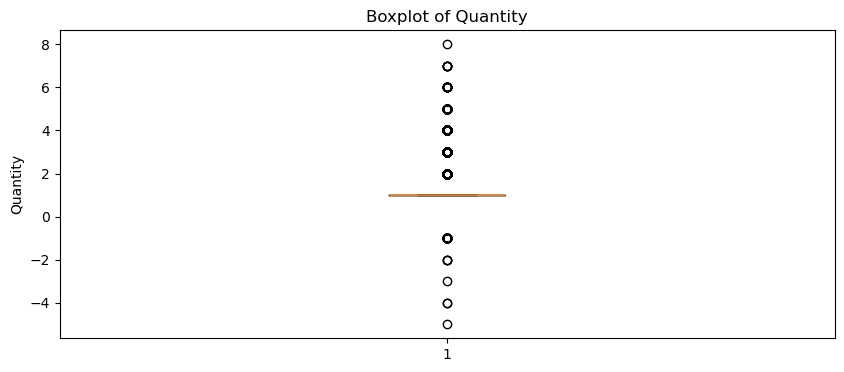

In [32]:
#investigating outliers
plt.figure(figsize=(10, 4))

plt.boxplot(df['Quantity'])

plt.ylabel('Quantity')
plt.title('Boxplot of Quantity')

plt.show()

the box is relatively very narrow, this suggests the quatity values are concentrated around a small range
many transactionshave similar relatively small quantities

In [33]:
Q1 = df['Quantity'].quantile(0.25)
Q3 = df['Quantity'].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower bound:", lower_bound)
print("Upper bound:", upper_bound)

Q1: 1.0
Q3: 1.0
IQR: 0.0
Lower bound: 1.0
Upper bound: 1.0


In [34]:
outliers = df[
    (df['Quantity'] < lower_bound) |
    (df['Quantity'] > upper_bound)
]

print("Number of outliers:", len(outliers))

Number of outliers: 1257


In [36]:
#checking the number of items each customer has purchased
customer_quantity = (
    df.groupby('CustomerID')['Quantity']
    .sum()
    .sort_values(ascending=False)
)

customer_quantity.head(20)

CustomerID
C0313    34
C0397    34
C1422    32
C1750    31
C1551    31
C0981    30
C0820    30
C1302    30
C0170    29
C1706    29
C0764    29
C0940    29
C1250    28
C0067    28
C0354    28
C1058    27
C0970    27
C0057    27
C0907    27
C1674    27
Name: Quantity, dtype: int64

In [41]:
quantity_features = df.groupby('CustomerID').agg(
    total_quantity=('Quantity', 'sum'),
    average_quantity=('Quantity', 'mean'),
    median_quantity=('Quantity', 'median'),
    max_quantity=('Quantity', 'max'),
    min_quantity=('Quantity', 'min'),
    transaction_count=('Quantity', 'count'),
    quantity_std=('Quantity', 'std')
)

quantity_features.sort_index()

,total_quantity,average_quantity,median_quantity,max_quantity,min_quantity,transaction_count,quantity_std
CustomerID,,,,,,,
C0001,8,2.000000,1.0,5,1,4,2.000000
C0002,15,1.071429,1.0,2,1,14,0.267261
C0003,14,1.750000,1.0,4,1,8,1.164965
C0004,3,1.500000,1.5,2,1,2,0.707107
C0005,1,1.000000,1.0,1,1,1,NaN
...,...,...,...,...,...,...,...
C1846,11,1.100000,1.0,2,1,10,0.316228
C1847,3,1.000000,1.0,1,1,3,0.000000
C1848,1,1.000000,1.0,1,1,1,NaN


In [46]:
#Quantity by Customer spending
customer_spending = (
    df.groupby('CustomerID')['TotalAmount']
    .sum()
    .rename('total_spending')
)

customer_spending

CustomerID
C0001     421.60
C0002    3038.91
C0003    1200.31
C0004     136.24
C0005      68.88
          ...   
C1846    2211.74
C1847     617.96
C1848      14.41
C1849     101.92
C1850    1755.91
Name: total_spending, Length: 1847, dtype: float64

In [48]:
customer_analysis = quantity_features.join(customer_spending)
customer_analysis.head()

,total_quantity,average_quantity,median_quantity,max_quantity,min_quantity,transaction_count,quantity_std,total_spending
CustomerID,,,,,,,,
C0001,8,2.000000,1.0,5,1,4,2.000000,421.60
C0002,15,1.071429,1.0,2,1,14,0.267261,3038.91
C0003,14,1.750000,1.0,4,1,8,1.164965,1200.31
C0004,3,1.500000,1.5,2,1,2,0.707107,136.24
C0005,1,1.000000,1.0,1,1,1,NaN,68.88


In [50]:
#checking the correlation btwn total quantity and total spending
customer_analysis[
    ['total_quantity', 'average_quantity',
     'transaction_count', 'total_spending']
].corr()

,total_quantity,average_quantity,transaction_count,total_spending
total_quantity,1.000000,0.165727,0.963477,0.866818
average_quantity,0.165727,1.000000,-0.012422,0.053084
transaction_count,0.963477,-0.012422,1.000000,0.875562
total_spending,0.866818,0.053084,0.875562,1.000000


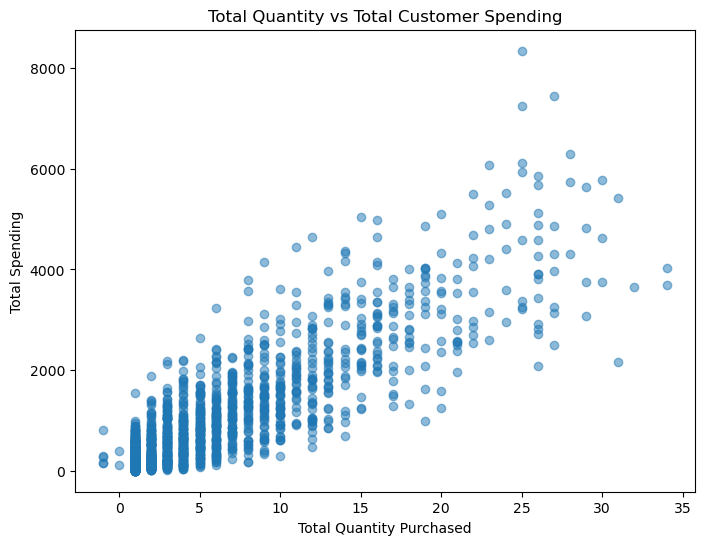

In [51]:
#visualizing total quantity with total spending
plt.figure(figsize=(8, 6))

plt.scatter(
    customer_analysis['total_quantity'],
    customer_analysis['total_spending'],
    alpha=0.5
)

plt.xlabel('Total Quantity Purchased')
plt.ylabel('Total Spending')
plt.title('Total Quantity vs Total Customer Spending')

plt.show()